## 练习开发一个多功能智能体助手
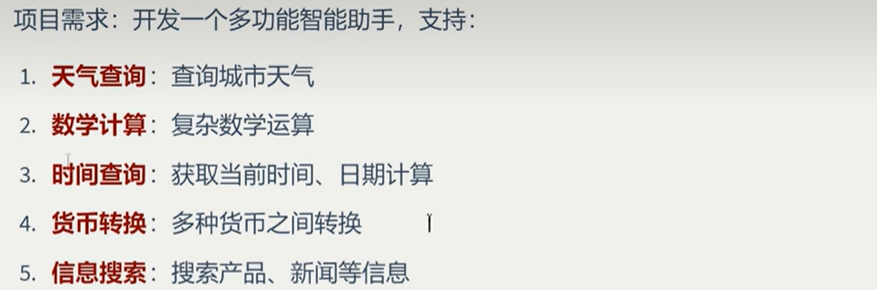


### 初始化模型

In [9]:
import time
from langchain_core.tools import tool
from typing import Union, Dict, Any
from langchain_openai import ChatOpenAI
from langchain.agents import create_agent
from langgraph.config import get_stream_writer
from rich import print as rprint
# 1.初始化模型
model = ChatOpenAI(
    # model="carstenuhlig/omnicoder-9b:latest",
    # model="qwen3-vl:latest",
    model="483025889/qwen3.5:9b",
    api_key="sk12345",
    base_url="http://localhost:11434/v1",
)


## 2.准备工具



In [10]:
from datetime import datetime, timedelta
import math
from tool_utils import query_weather_from_web,query_news_from_web

@tool
def calculator(expression: str) ->str:
    """执行数学计算

      支持基本运算(+，-，*，/，**）和常用数学函数

      Args:
           expression: 数学表达式，可以包含：
                  - 基本运算： 2+3，10 * 5，100/4
                  - 幂运算： 2 ** 10
                  - 函数：sqrt(16),abs(-5),pow(2,3)

      Returns:
             计算结果或错误信息

     Examples:
            calculator("2 + 3 * 4") 返回  "14"
     """
    try:
        # 安全数学运算环境
        safe_functions= {
             "sqrt": math.sqrt,
             "pow": pow,
             "abs": abs,
              "round":round,
              "sin": math.sin,
              "cos": math.cos,
              "tan": math.tan,
              "log": math.log,
              "pi": math.pi,
               "e": math.e
         }

        result = eval(expression,{"__builtins__":{}},safe_functions)
        return f"{expression}={result}"
    except Exception as e:
            return f"计算出错：{str(e)}\n提示：请检查表达式格式，支持的格式有sqrt，abs,pow,sin,cos,tan,log"


@tool
def get_time_info(query_type: str = "current") -> str:
    """获取时间相关信息

    Args:
        query_type: 查询类型
            -"current": 当前时间
            -"date": 今天日期
            -"tomorrow": 明天日期
            -"yesterday": 昨天日期
            -"weekday": 星期几

    Returns：
         时间信息字符串

    Examples：
        get_time_info("current") 返回 "2026年10月12日 20：20：20"
        get_time_info("weekday") 返回 "星期一"

    """
    now = datetime.now()
    if query_type == "current":
        return now.strftime("当前时间：%Y年%m月%d日 %H:%M:%S")
    elif query_type == "date":
        return now.strftime("今天是：%Y年%m月%d日")
    elif query_type == "tomorrow":
        tomorrow = now + timedelta(days=1)
        return tomorrow.strftime("明天是：%Y年%m月%d日")
    elif query_type == "yesterday":
        yesterday = now - timedelta(days=1)
        return yesterday.strftime("昨天是：%Y年%m月%d日")
    elif query_type=="weekday":
        weekdays = ["星期一","星期二","星期三","星期四","星期五","星期六","星期日"]
        return f"今天是{weekdays[now.weekday()]}"
    else:
        return f"不支持的查询类型：{query_type}.支持：current，date,tomorrow,yesterday,weekday"


@tool
def convert_currency(amount:float,from_curr: str,to_curr:str) -> str:
    """货币转换工具
    支持主要货币之间的实时汇率转换

    Args:
        amount: 金额数值
        from_curr： 源货币代码(CNY/USD/EUR/JPY/HKD)
        to_curr： 目标货币代码(CNY/USD/EUR/JPY/HKD)

    Returns:
        转换结果

    Examples:
        convert_currency(100,"CNY","USD") 返回 "100 CNY = 14.00 USD"
    """

    # 汇率表(相对于CNY)
    exchange_rates = {
        "CNY":1.0,     # 人民币
        "USD":0.14,     # 美元
        "EUR":0.13,     # 欧元
        "GBP":0.11,     # 英镑
        "JPY":20.8,     # 日元
        "HKD":1.09,     # 港币

    }

    # 货币名称
    currency_names = {
           "CNY": "人民币",
            "USD": "美元",
            "EUR": "欧元",
            "GBP": "英镑",
            "JPY": "日元",
            "HKD":"港币"
    }

    from_curr = from_curr.upper()
    to_curr = to_curr.upper()

    if from_curr not in exchange_rates:
        return f"不支持的源货币：{from_curr}. 支持的货币：CNY,USD,EUR,GBP,JPY,HKD"
    if to_curr not in exchange_rates:
            return f"不支持的源货币：{to_curr}. 支持的货币：CNY,USD,EUR,GBP,JPY,HKD"

    # 转换逻辑，先转为CNY,再转为目标货币
    cny_amount = amount/exchange_rates[from_curr]
    result_amount = cny_amount * exchange_rates[to_curr]

    from_name = currency_names[from_curr]
    to_name = currency_names[to_curr]
    return f"{amount} {from_name} ({from_curr}) = {result_amount} {to_name} ({to_curr})"

@tool
def search_info(kw: str,category:str = "all") -> str:
    """搜索各类信息

    Args:
        kw: 搜索关键词
        category: 搜索分类
            - "product": 搜索产品
            - "news": 搜索新闻
            - "all": 搜索所有

    Returns:
        搜索结果
    """
    # 模拟数据库
    products={
       "手机":"IPhone 15 (￥5999)，小米14(￥3999)，华为Mate60(￥6999)",
       "笔记本": "MacBook Pro (￥12999),ThinkPad X1 (￥9999),华为MateBook (￥7999)",
       "耳机":"AirPods Pro (￥1999),Sony WH-1000XM5 (￥2499)"
    }

    news = {
       "AI":"1.GPT-5即将发布  2.AI 芯片市场增长 30%  3.新AI法规出台",
       "科技":"1.量子计算新突破  2.6G 计算测试  3.新能源汽车销量创新高"
    }

    result = []
    if category in ["product","all"]:
        for k,v in products.items():
            if kw in k:
                result.append(f"[产品]{k}:{v}")

    if category in ["news","all"]:
        for k,v in news.items():
            if kw in k:
                result.append(f"[新闻]{k}相关:{v}")

        if result:
            return "\n".join(result)
        else:
            return f"未找到关于'{kw}'的{category}信息"


## 3.创建智能体对象，model、tools、system_prompt、ToolStrategy(实现结构化生成)；invoke --->消息列表
### 使用面向对象的编程方式

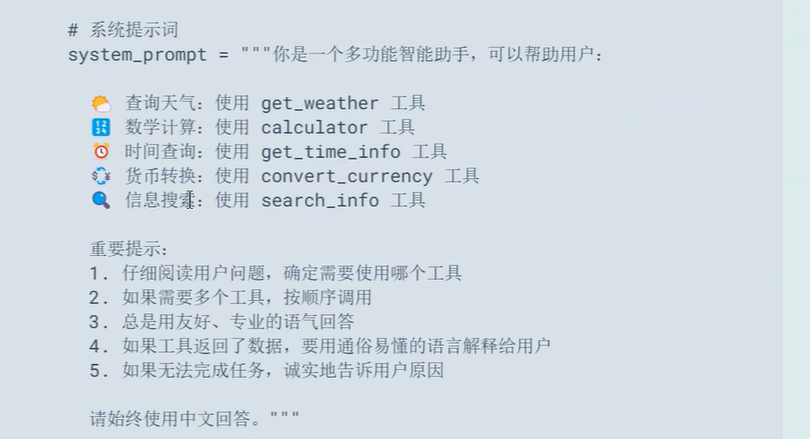

In [11]:
class SmartAssistant:
    """多功能智能助手"""
    def __init__(self):
        # 初始化模型
        self.model = model

        # 工具列表
        self.tools = [
            query_weather_from_web,
            calculator,
            get_time_info,
            convert_currency,
            search_info
        ]

        # 系统提示词
        system_prompt = """你是一个多功能智能助手，可以帮助用户：

            查询天气：使用 query_weather_from_web 工具
            数学计算：使用 calculator 工具
            时间查询：使用 get_time_info 工具
            货币转换：使用 convert_currency 工具
            信息搜索：使用 search_info 工具

        重要提示：
        1.仔细阅读用户问题，确定需要使用哪个工具
        2.如果需要多个工具，按顺序调用
        3.总是用友好、专业的语气回答
        4.如果工具返回了数据，要用通俗易懂的语言解析给用户
        5.如果无法完成任务，诚实的告诉用户原因

        请始终用中文回答"""

        self.agent = create_agent(
            model = self.model,
            tools = self.tools,
            system_prompt = system_prompt

        )

        # 对话历史
        self.messages = []

    def chat(self,user_input:str) -> str:
        """对话接口"""
        # 添加用户信息
        self.messages.append({"role":"user","content":user_input})

        # 调用agent
        result = self.agent.invoke({"messages":self.messages})
        # 更新消息历史
        self.messages = result["messages"]
        # 返回最后一条 AI 消息
        for msg in reversed(self.messages):
            if msg.type == "ai" and msg.content:
                return msg.content
        return "抱歉，我无法处理这个请求"

    def reset(self):
        """重置对话历史"""
        self.messages = []

## 4.主程序，测试agent

### 交互模式代码
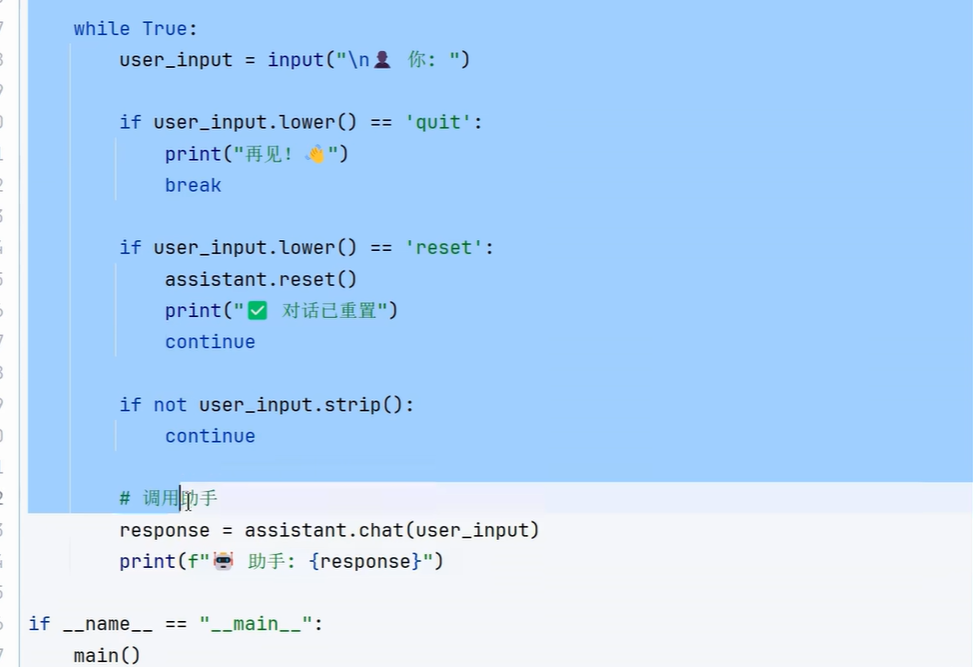

### 测试1，非交互模式


In [12]:
# assist = SmartAssistant()
#
# demos = [
#     "北京今天的天气怎么样？",
#     "帮我算一下(25+17)*3",
#     "现在几点了？",
#     "100美元等于多少人民币？"
# ]
#
# for demo in demos:
#     print(f"用户：{demo}")
#     response= assist.chat(demo)
#     print(f"AI:{response}")
#
# assist.reset()

### 交互模式


In [13]:
print("=======================多功能智能助手========================")
print("""你好，我可以帮你：

        查询天气
        数学计算
        时间查询
        货币转换
        信息搜索
""")
print("\n输入quit退出，输入reset重置对话\n")
assist = SmartAssistant()

while True:
    user_input = input("\n 你：")
    print(f"用户输入{user_input}")
    if user_input.lower() == "quit":
        print("欢迎你下次使用，再见！")
        break
    if user_input.lower() == "reset":
        print("已经重置")
        assist.reset()
        continue
    if not user_input.strip():
        continue

    ## 调用助手
    resp = assist.chat(user_input)
    print(f"AI:{resp}")






=======================多功能智能助手========================
你好，我可以帮你：

        查询天气
        数学计算
        时间查询
        货币转换
        信息搜索


输入quit退出，输入reset重置对话

AI:根据实时汇率，150 美元可以兑换成约 **1071.43 人民币**。

这个结果是按照当前美元兑人民币的汇率计算的，具体为：
- 150.0 美元 (USD) = 1071.43 人民币 (CNY)

汇率是实时变动的，所以具体的兑换金额可能会随时间有所变化。如果您需要进行实际的货币转换，建议通过银行或正规交易平台进行办理哦！
AI:根据查询结果，上海今天的天气情况如下：

🌤️ **天气状况**：晴朗

🌡️ **当前温度**：19.4°C (约 67°F)

💨 **风速**：15.5 km/h（风向 NNE）

💧 **湿度**：63%

☔ **降水概率**：仅 4%，下雨的可能性很小

👀 **能见度**：10公里，视野清晰

**温馨提示**：
- 今天天气晴朗，体感温度大约为17°C，早晚可能会稍凉一些，建议适当增减衣物。
- 空气比较干燥，湿度适中，适合外出活动。
- 目前风力不大，不用担心刮风影响出行。

如果您有具体的出行计划或需要其他地区的天气信息，随时告诉我哦！
AI:好的，我会结束当前的服务。如果您未来还有其他需求或问题，欢迎随时回来使用我的多功能智能助手服务！祝您生活愉快！👋
欢迎你下次使用，再见！
